# Analisis Data Pertumbuhan *Gracilaria* sp.

Notebook ini membaca file `Dataset_Gracilaria_Sederhana.xlsx` yang diisi dari jurnal penelitian.

**Penting:** template Excel sengaja kosong. Notebook tidak membuat data penelitian palsu. Hasil analisis baru bermakna setelah data jurnal dimasukkan dan diperiksa.

Alur: membaca data → pemeriksaan → menghitung SGR (jika data cocok) → EDA → regresi → klasifikasi eksploratif → PCA dan K-Means.

Satu baris harus mewakili satu pengamatan untuk satu perlakuan pada satu waktu. Data dari satu jurnal memiliki kode jurnal yang sama.

## 1. Instalasi dan import library

In [ ]:
# Jika menjalankan di Google Colab, aktifkan baris berikut bila library belum tersedia:
# !pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option("display.max_columns", None)
sns.set_theme()


## 2. Membaca file Excel

In [ ]:
# Pastikan file Excel berada di folder kerja yang sama dengan notebook.
FILE_EXCEL = "Dataset_Gracilaria_Sederhana.xlsx"

df = pd.read_excel(FILE_EXCEL, sheet_name="Data Pertumbuhan")
sumber = pd.read_excel(FILE_EXCEL, sheet_name="Daftar Jurnal")

# Hilangkan baris template yang belum diisi
df = df.dropna(subset=["Kode Jurnal"], how="any").copy()

print("Jumlah baris data:", len(df))
display(df.head())


Jumlah baris data: 15


,Nomor Data,Kode Jurnal,Tahun Jurnal,Jenis Gracilaria,Metode Budidaya,Lama Budidaya (hari),Hari Pengamatan,Berat Awal (gram),Berat Akhir (gram),Suhu Air (°C),pH Air,Salinitas (ppt),Oksigen Terlarut (mg/L),Nitrat (mg/L),Fosfat (mg/L),Laju Pertumbuhan (%/hari),Sumber Data,Halaman Jurnal,Keterangan
0,GR001,109737,2019,Gracilaria verrucosa,Tambak,42,42,50,185.4,29.0,7.5,29,4.4,0.285,0.09,3.12,NaN,NaN,NaN
1,GR002,109737,2019,Gracilaria verrucosa,Tambak,42,42,75,210.2,29.0,7.5,29,4.4,0.285,0.09,3.42,NaN,NaN,NaN
2,GR003,109737,2019,Gracilaria verrucosa,Tambak,42,42,100,245.8,29.0,7.5,29,4.4,0.285,0.09,3.79,NaN,NaN,NaN
3,GR004,109737,2019,Gracilaria verrucosa,Tambak,42,42,125,228.5,29.0,7.5,29,4.4,0.285,0.09,3.62,NaN,NaN,NaN
4,GR005,89173003,2015,Gracilaria verrucosa,Tambak,45,45,100,340.5,29.0,7.9,26,3.8,0.090,0.08,2.72,NaN,NaN,NaN


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. Pemeriksaan dan pembersihan awal

In [ ]:
print("Ukuran dataset:", df.shape)
print("\nTipe data:")
display(df.dtypes)
print("\nJumlah data kosong:")
display(df.isna().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())

# Ubah kolom numerik menjadi angka; nilai yang tidak terbaca menjadi NaN
kolom_angka = [
    "Tahun Jurnal", "Lama Budidaya (hari)", "Hari Pengamatan",
    "Berat Awal (gram)", "Berat Akhir (gram)", "Suhu Air (°C)",
    "pH Air", "Salinitas (ppt)", "Oksigen Terlarut (mg/L)",
    "Nitrat (mg/L)", "Fosfat (mg/L)", "Laju Pertumbuhan (%/hari)"
]
for kolom in kolom_angka:
    df[kolom] = pd.to_numeric(df[kolom], errors="coerce")

# Hapus duplikat persis, bukan pengamatan yang hanya kebetulan memiliki nilai sama
df = df.drop_duplicates().copy()


Ukuran dataset: (15, 19)

Tipe data:


,0
Nomor Data,object
Kode Jurnal,int64
Tahun Jurnal,int64
Jenis Gracilaria,object
Metode Budidaya,object
Lama Budidaya (hari),int64
Hari Pengamatan,int64
Berat Awal (gram),int64
Berat Akhir (gram),float64
Suhu Air (°C),float64



Jumlah data kosong:


,0
Nomor Data,0
Kode Jurnal,0
Tahun Jurnal,0
Jenis Gracilaria,0
Metode Budidaya,0
Lama Budidaya (hari),0
Hari Pengamatan,0
Berat Awal (gram),0
Berat Akhir (gram),0
Suhu Air (°C),0



Jumlah baris duplikat: 0


## 4. Menghitung laju pertumbuhan spesifik (SGR), bila sesuai

Rumus yang digunakan:

\[
SGR = \frac{\ln(W_t)-\ln(W_0)}{t}\times 100
\]

Perhitungan hanya dilakukan jika berat awal dan berat akhir positif, lama waktu tersedia, serta kedua berat memakai basis yang sama (misalnya sama-sama berat basah). Pastikan rumus ini sesuai dengan definisi yang digunakan dalam penelitian.

In [ ]:
syarat_sgr = (
    df["Berat Awal (gram)"].gt(0) &
    df["Berat Akhir (gram)"].gt(0) &
    df["Hari Pengamatan"].gt(0)
)

# Hitung hanya untuk baris yang SGR-nya belum tersedia.
# Pastikan Hari Pengamatan adalah selang waktu dari penimbangan awal ke akhir.
hitung = syarat_sgr & df["Laju Pertumbuhan (%/hari)"].isna()
df.loc[hitung, "Laju Pertumbuhan (%/hari)"] = (
    (np.log(df.loc[hitung, "Berat Akhir (gram)"]) -
     np.log(df.loc[hitung, "Berat Awal (gram)"])) /
    df.loc[hitung, "Hari Pengamatan"] * 100
)

display(df[["Kode Jurnal", "Hari Pengamatan", "Berat Awal (gram)",
            "Berat Akhir (gram)", "Laju Pertumbuhan (%/hari)"]].head())


,Kode Jurnal,Hari Pengamatan,Berat Awal (gram),Berat Akhir (gram),Laju Pertumbuhan (%/hari)
0,109737,42,50,185.4,3.12
1,109737,42,75,210.2,3.42
2,109737,42,100,245.8,3.79
3,109737,42,125,228.5,3.62
4,89173003,45,100,340.5,2.72


## 5. Exploratory Data Analysis (EDA)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Nomor Data,15,15,GR001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Kode Jurnal,15.0,NaN,NaN,NaN,40732554.4,38606886.045071,109737.0,424004.5,63672802.0,69251138.0,89173003.0
Tahun Jurnal,15.0,NaN,NaN,NaN,2018.8,2.704494,2015.0,2018.0,2019.0,2019.5,2024.0
Jenis Gracilaria,15,1,Gracilaria verrucosa,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Metode Budidaya,15,2,Tambak,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Lama Budidaya (hari),15.0,NaN,NaN,NaN,50.6,15.765242,42.0,43.5,45.0,49.0,105.0
Hari Pengamatan,15.0,NaN,NaN,NaN,50.6,15.765242,42.0,43.5,45.0,49.0,105.0
Berat Awal (gram),15.0,NaN,NaN,NaN,66784.0,258166.455199,10.0,75.0,100.0,137.5,1000000.0
Berat Akhir (gram),15.0,NaN,NaN,NaN,953496.684667,3691369.025382,121.0,205.935,245.8,520.1,14297000.0
Suhu Air (°C),15.0,NaN,NaN,NaN,29.405333,0.967396,29.0,29.0,29.0,29.25,32.58


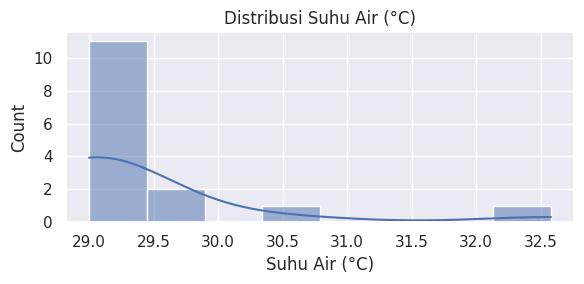

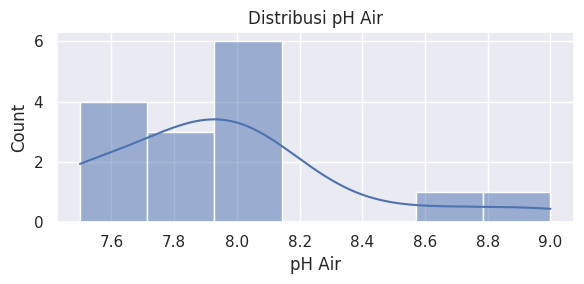

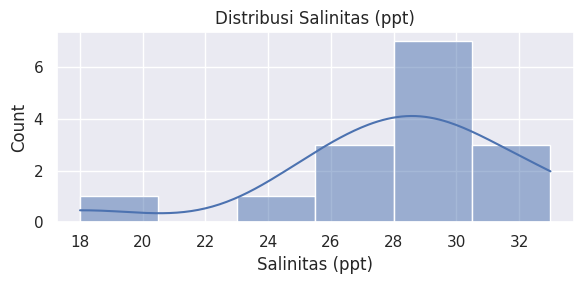

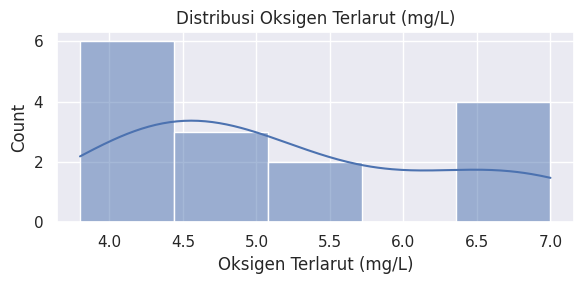

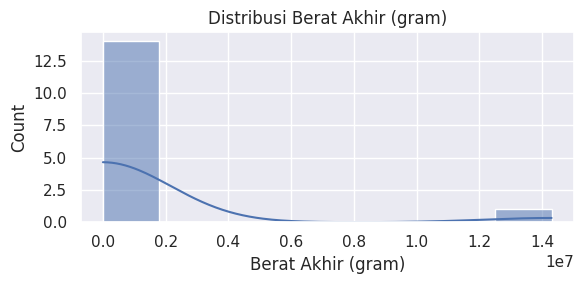

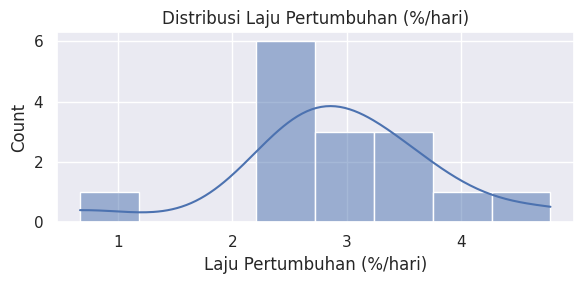

In [ ]:
display(df.describe(include="all").T)

kolom_plot = ["Suhu Air (°C)", "pH Air", "Salinitas (ppt)",
              "Oksigen Terlarut (mg/L)", "Berat Akhir (gram)",
              "Laju Pertumbuhan (%/hari)"]
tersedia = [c for c in kolom_plot if c in df.columns and df[c].notna().any()]

for c in tersedia:
    plt.figure(figsize=(6, 3))
    sns.histplot(df[c].dropna(), kde=True)
    plt.title(f"Distribusi {c}")
    plt.tight_layout()
    plt.show()


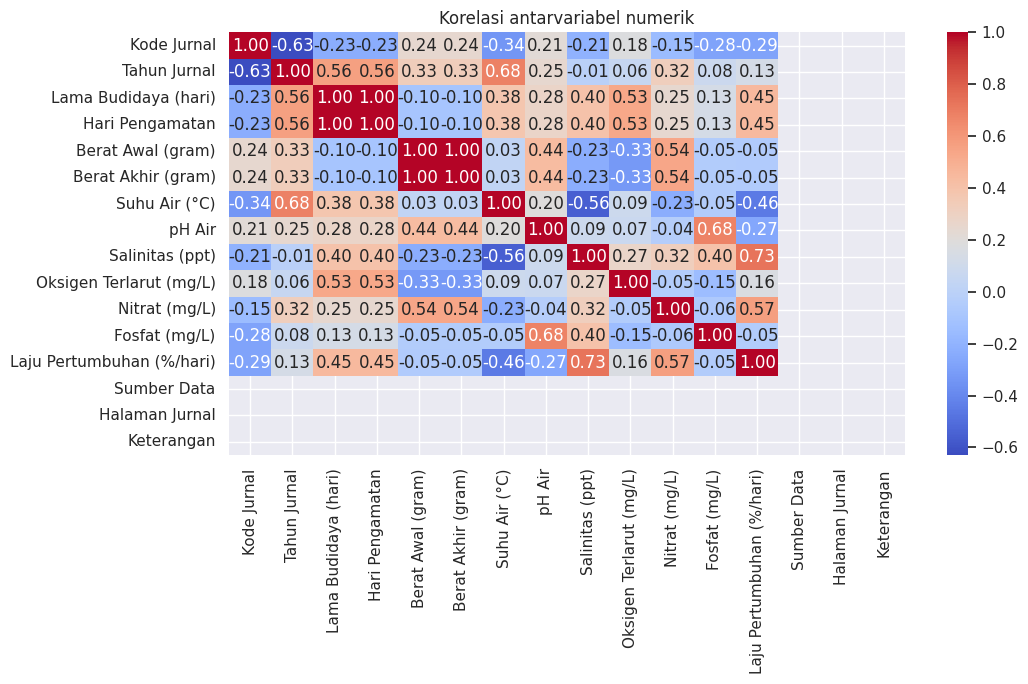

In [ ]:
# Korelasi numerik untuk melihat pola awal, bukan bukti sebab-akibat
numerik = df.select_dtypes(include=np.number)
if numerik.shape[1] >= 2:
    plt.figure(figsize=(11, 7))
    sns.heatmap(numerik.corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Korelasi antarvariabel numerik")
    plt.tight_layout()
    plt.show()
else:
    print("Belum cukup kolom numerik untuk membuat korelasi.")


## 6. Supervised learning: regresi untuk memperkirakan SGR

Model hanya dijalankan jika tersedia cukup data berlabel. Pembagian data dilakukan berdasarkan **Kode Jurnal**, sehingga baris dari jurnal yang sama tidak tersebar ke data latih dan uji.

Dengan jumlah jurnal yang sangat sedikit, evaluasi model tidak akan stabil. Hasil harus dianggap eksploratif.

In [ ]:
fitur_regresi = [
    "Suhu Air (°C)", "pH Air", "Salinitas (ppt)",
    "Oksigen Terlarut (mg/L)", "Nitrat (mg/L)", "Fosfat (mg/L)",
    "Lama Budidaya (hari)", "Hari Pengamatan", "Berat Awal (gram)"
]
target_regresi = "Laju Pertumbuhan (%/hari)"

reg = df.dropna(subset=[target_regresi, "Kode Jurnal"]).copy()
fitur_regresi = [c for c in fitur_regresi if c in reg.columns and reg[c].notna().any()]

if len(reg) >= 10 and reg["Kode Jurnal"].nunique() >= 2 and len(fitur_regresi) >= 2:
    X = reg[fitur_regresi]
    y = reg[target_regresi]
    groups = reg["Kode Jurnal"]

    splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
    train_idx, test_idx = next(splitter.split(X, y, groups=groups))
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    model_reg = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", RandomForestRegressor(n_estimators=200, random_state=42))
    ])
    model_reg.fit(X_train, y_train)
    pred = model_reg.predict(X_test)

    print("MAE:", mean_absolute_error(y_test, pred))
    print("RMSE:", mean_squared_error(y_test, pred) ** 0.5)
    print("R2:", r2_score(y_test, pred))
else:
    print("Regresi dilewati: perlu minimal 10 baris berlabel, minimal 2 kode jurnal, dan minimal 2 fitur yang tersedia.")


MAE: 0.6277599999999964
RMSE: 0.7509450898700879
R2: -2.6602874649495947


## 7. Supervised learning: klasifikasi kategori pertumbuhan

Kategori rendah/sedang/tinggi dibuat dari pembagian nilai SGR menjadi tiga kelompok (tercile). Ini adalah kategori relatif dalam dataset, bukan standar biologis universal. Ambang batas dihitung dari data latih saja.

Klasifikasi juga memakai pemisahan berdasarkan kode jurnal.

In [ ]:
klas = df.dropna(subset=[target_regresi, "Kode Jurnal"]).copy() if "target_regresi" in globals() else df.dropna(subset=["Laju Pertumbuhan (%/hari)", "Kode Jurnal"]).copy()
target_sgr = "Laju Pertumbuhan (%/hari)"
fitur_klas = [c for c in fitur_regresi if c in klas.columns and c != "Berat Akhir (gram)"]

if len(klas) >= 15 and klas["Kode Jurnal"].nunique() >= 2 and len(fitur_klas) >= 2:
    X = klas[fitur_klas]
    y_cont = klas[target_sgr]
    groups = klas["Kode Jurnal"]

    splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
    train_idx, test_idx = next(splitter.split(X, y_cont, groups=groups))
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train_cont, y_test_cont = y_cont.iloc[train_idx], y_cont.iloc[test_idx]

    batas = y_train_cont.quantile([1/3, 2/3]).values
    def buat_kategori(v):
        return pd.cut(v, bins=[-np.inf, batas[0], batas[1], np.inf],
                      labels=["Rendah", "Sedang", "Tinggi"], include_lowest=True)

    y_train = buat_kategori(y_train_cont)
    y_test = buat_kategori(y_test_cont)

    if y_train.nunique() >= 2:
        model_klas = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", RandomForestClassifier(n_estimators=200, random_state=42,
                                             class_weight="balanced"))
        ])
        model_klas.fit(X_train, y_train)
        pred_klas = model_klas.predict(X_test)
        print("Akurasi:", accuracy_score(y_test, pred_klas))
        print("F1 macro:", f1_score(y_test, pred_klas, average="macro", zero_division=0))
        print(classification_report(y_test, pred_klas, zero_division=0))
        print("Batas kategori SGR dari data latih:", batas)
    else:
        print("Klasifikasi dilewati: data latih hanya memiliki satu kategori.")
else:
    print("Klasifikasi dilewati: data berlabel atau jumlah jurnal belum mencukupi.")


Akurasi: 0.0
F1 macro: 0.0
              precision    recall  f1-score   support

      Rendah       0.00      0.00      0.00       0.0
      Sedang       0.00      0.00      0.00       1.0
      Tinggi       0.00      0.00      0.00       4.0

    accuracy                           0.00       5.0
   macro avg       0.00      0.00      0.00       5.0
weighted avg       0.00      0.00      0.00       5.0

Batas kategori SGR dari data latih: [2.59 2.75]


## 8. Unsupervised learning: PCA dan K-Means

Analisis ini menggunakan variabel kualitas air yang tersedia. Baris yang seluruh fiturnya kosong akan dibuang. K-Means membutuhkan jumlah pengamatan yang cukup dan beberapa jurnal/perlakuan yang beragam.

Cluster adalah kelompok kemiripan statistik, bukan otomatis kategori kualitas air baik/buruk.

Proporsi variasi PCA: [0.31847503 0.27692003]
Silhouette score: 0.46551025977742894


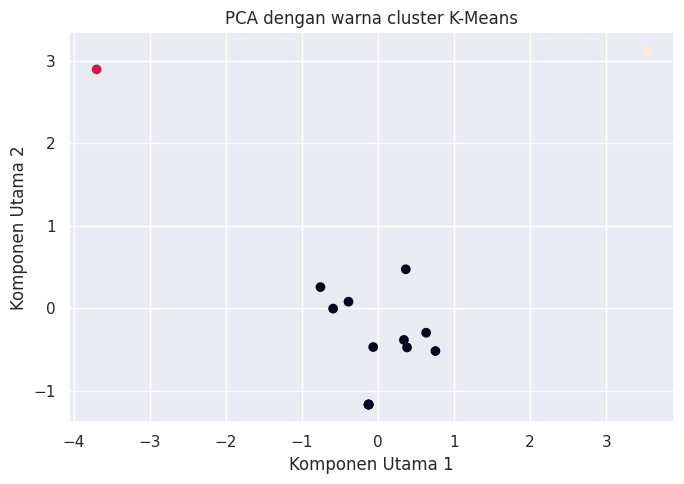

,Kode Jurnal,Cluster,Suhu Air (°C),pH Air,Salinitas (ppt),Oksigen Terlarut (mg/L),Nitrat (mg/L),Fosfat (mg/L)
0,109737,0,29.0,7.5,29,4.4,0.285,0.09
1,109737,0,29.0,7.5,29,4.4,0.285,0.09
2,109737,0,29.0,7.5,29,4.4,0.285,0.09
3,109737,0,29.0,7.5,29,4.4,0.285,0.09
4,89173003,0,29.0,7.9,26,3.8,0.090,0.08


In [ ]:
fitur_cluster = [
    "Suhu Air (°C)", "pH Air", "Salinitas (ppt)",
    "Oksigen Terlarut (mg/L)", "Nitrat (mg/L)", "Fosfat (mg/L)"
]
fitur_cluster = [c for c in fitur_cluster if c in df.columns and df[c].notna().any()]
clu = df.dropna(subset=["Kode Jurnal"]).copy()

if len(fitur_cluster) >= 2 and len(clu) >= 6:
    Xc = clu[fitur_cluster]
    prep = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    Xc_scaled = prep.fit_transform(Xc)

    pca = PCA(n_components=2, random_state=42)
    pcs = pca.fit_transform(Xc_scaled)
    print("Proporsi variasi PCA:", pca.explained_variance_ratio_)

    jumlah_cluster = min(3, len(clu)-1)
    if jumlah_cluster >= 2:
        km = KMeans(n_clusters=jumlah_cluster, random_state=42, n_init=10)
        labels = km.fit_predict(Xc_scaled)
        print("Silhouette score:", silhouette_score(Xc_scaled, labels) if len(set(labels)) > 1 else "Tidak tersedia")

        plt.figure(figsize=(7, 5))
        plt.scatter(pcs[:, 0], pcs[:, 1], c=labels)
        plt.xlabel("Komponen Utama 1")
        plt.ylabel("Komponen Utama 2")
        plt.title("PCA dengan warna cluster K-Means")
        plt.tight_layout()
        plt.show()

        clu["Cluster"] = labels
        display(clu[["Kode Jurnal", "Cluster"] + fitur_cluster].head())
else:
    print("PCA/K-Means dilewati: perlu minimal 2 fitur kualitas air dan 6 baris data.")


## 9. Menyimpan dataset hasil pembersihan

In [ ]:
file_output = "Data_Gracilaria_Bersih.xlsx"
df.to_excel(file_output, index=False)
print("File tersimpan:", file_output)


File tersimpan: Data_Gracilaria_Bersih.xlsx


In [ ]:
target = "Laju Pertumbuhan (%/hari)"

# Membersihkan spasi pada kode jurnal
df["Kode Jurnal"] = (
    df["Kode Jurnal"]
    .astype("string")
    .str.strip()
)

# Data yang akan digunakan untuk klasifikasi
klas_cek = df.dropna(
    subset=[target, "Kode Jurnal"]
).copy()

print("Jumlah seluruh baris:", len(df))
print("Jumlah data dengan SGR:", df[target].notna().sum())
print("Jumlah baris untuk klasifikasi:", len(klas_cek))

print("\nJumlah jurnal unik:",
      klas_cek["Kode Jurnal"].nunique())

print("\nDaftar kode jurnal:")
print(klas_cek["Kode Jurnal"].value_counts())

print("\nJumlah variabel prediktor:")

fitur_cek = [
    "Suhu Air (°C)", "pH Air", "Salinitas (ppt)",
    "Oksigen Terlarut (mg/L)", "Nitrat (mg/L)",
    "Fosfat (mg/L)", "Lama Budidaya (hari)",
    "Hari Pengamatan", "Berat Awal (gram)"
]

fitur_tersedia = [
    c for c in fitur_cek
    if c in klas_cek.columns and klas_cek[c].notna().any()
]

print(len(fitur_tersedia))
print(fitur_tersedia)

Jumlah seluruh baris: 15
Jumlah data dengan SGR: 15
Jumlah baris untuk klasifikasi: 15

Jumlah jurnal unik: 7

Daftar kode jurnal:
Kode Jurnal
109737      4
63672802    4
89173003    3
738272      1
74829474    1
6276423     1
6494982     1
Name: count, dtype: Int64

Jumlah variabel prediktor:
9
['Suhu Air (°C)', 'pH Air', 'Salinitas (ppt)', 'Oksigen Terlarut (mg/L)', 'Nitrat (mg/L)', 'Fosfat (mg/L)', 'Lama Budidaya (hari)', 'Hari Pengamatan', 'Berat Awal (gram)']


## 10. Catatan interpretasi dan keterbatasan

- Data berasal dari publikasi yang berbeda, sehingga metode, lokasi, strain/spesies, dan kondisi eksperimen bisa berbeda.
- Jangan menganggap hubungan statistik sebagai hubungan sebab-akibat.
- Jangan menggabungkan biomassa basah dan kering tanpa konversi yang sah.
- Data yang dibaca dari grafik harus ditandai sebagai estimasi.
- Jika hanya ada sedikit jurnal independen, performa model belum dapat digeneralisasi.
- Biomassa tinggi tidak otomatis berarti siap panen. Prediksi kesiapan panen membutuhkan label panen dan kriteria biologis/operasional yang tervalidasi.